In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterSampler
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv("../data/processed/fe_data.csv")

In [3]:
# Splitting into three dataset
df_train = df[df["datetime"] < "2016-01-01"]
df_val = df[(df["datetime"] >= "2016-01-01") & (df["datetime"] < "2016-11-01")]
df_test = df[df["datetime"] >= "2016-11-01"]

print(f"Train set: {df_train.shape}")
print(f"Valid set: {df_val.shape}")
print(f"Test set: {df_test.shape}")

Train set: (70980, 47)
Valid set: (21161, 47)
Test set: (8637, 47)


In [4]:
# Splitting target column
X_train = df_train.drop(["target_pm25_1h", "datetime", "year", "month", "day", "hour"], axis=1)
y_train = df_train["target_pm25_1h"]

X_val = df_val.drop(["target_pm25_1h", "datetime", "year", "month", "day", "hour"], axis=1)
y_val = df_val["target_pm25_1h"]

X_test = df_test.drop(["target_pm25_1h", "datetime", "year", "month", "day", "hour"], axis=1)
y_test = df_test["target_pm25_1h"]

print(f"Train set: {X_train.shape}, {y_train.shape}")
print(f"Valid set: {X_val.shape}, {y_val.shape}")
print(f"Test set: {X_test.shape}, {y_test.shape}")

Train set: (70980, 41), (70980,)
Valid set: (21161, 41), (21161,)
Test set: (8637, 41), (8637,)


In [5]:
def evaluate_predictions(y_true, y_pred, label=""):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"=== {label} ===")
    print(f"MAE:  {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²:   {r2:.4f}\n")
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2}

# Validation baseline
y_val_base = X_val['PM2.5']
val_base_metrics = evaluate_predictions(y_val, y_val_base, label="Naive Baseline (Validation)")

# Test baseline
y_test_base = X_test['PM2.5']
test_base_metrics = evaluate_predictions(y_test, y_test_base, label="Naive Baseline (Test)")

=== Naive Baseline (Validation) ===
MAE:  8.23
RMSE: 17.42
R²:   0.9207

=== Naive Baseline (Test) ===
MAE:  12.45
RMSE: 23.72
R²:   0.9410



In [6]:
models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(random_state=37),
    "Random Forest": RandomForestRegressor(random_state=37),
    "Gradient Boost": HistGradientBoostingRegressor(random_state=37)
}

In [7]:
# Search the best base model
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    pipe.fit(X_train, y_train)

    y_val_pred = pipe.predict(X_val)
    val_metrics = evaluate_predictions(y_val, y_val_pred, label=name)

=== Linear ===
MAE:  8.50
RMSE: 16.83
R²:   0.9260

=== Ridge ===
MAE:  8.50
RMSE: 16.83
R²:   0.9260

=== Random Forest ===
MAE:  8.08
RMSE: 16.89
R²:   0.9255

=== Gradient Boost ===
MAE:  7.84
RMSE: 16.88
R²:   0.9255



In [8]:
# Hyperparameter tuning with 15 iterations
param_grid = {
    'learning_rate': [0.03, 0.05, 0.1],
    'max_iter': [300, 500],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [20, 50, 100],
    'l2_regularization': [0.0, 1.0, 5.0]
}

param_list = list(ParameterSampler(param_grid, n_iter=15, random_state=42))

best_rmse = float('inf')
best_params = None
best_model = None

for i, params in enumerate(param_list, 1):
    model = HistGradientBoostingRegressor(
        **params,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=37
    )
    model.fit(X_train, y_train)

    y_val_pred = model.predict(X_val)
    val_rmse = root_mean_squared_error(y_val, y_val_pred)
    val_mae = mean_absolute_error(y_val, y_val_pred)

    print(f"Trial {i:2d} | RMSE: {val_rmse:.2f} | MAE: {val_mae:.2f} | Params: {params}")
    
    if val_rmse < best_rmse:
        best_rmse = val_rmse
        best_params = params
        best_model = model

print("\n=== Best Tuned HistGB on Validation ===")
print("Best Params:", best_params)
tuning_score = evaluate_predictions(y_val, best_model.predict(X_val), label="Tuned HistGB (Validation)")

Trial  1 | RMSE: 16.63 | MAE: 7.89 | Params: {'min_samples_leaf': 100, 'max_leaf_nodes': 31, 'max_iter': 500, 'learning_rate': 0.1, 'l2_regularization': 5.0}
Trial  2 | RMSE: 16.65 | MAE: 7.83 | Params: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 5.0}
Trial  3 | RMSE: 16.58 | MAE: 7.84 | Params: {'min_samples_leaf': 100, 'max_leaf_nodes': 31, 'max_iter': 300, 'learning_rate': 0.05, 'l2_regularization': 5.0}
Trial  4 | RMSE: 16.67 | MAE: 7.83 | Params: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 1.0}
Trial  5 | RMSE: 16.71 | MAE: 7.92 | Params: {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'max_iter': 300, 'learning_rate': 0.1, 'l2_regularization': 1.0}
Trial  6 | RMSE: 16.56 | MAE: 7.84 | Params: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 500, 'learning_rate': 0.05, 'l2_regularization': 0.0}
Trial  7 | RMSE: 16.66 | MAE: 7.87 | Params: {'min_

In [9]:
# Predict using the best model
y_test_pred = best_model.predict(X_test)
test_score = evaluate_predictions(y_test, y_test_pred, label="Tuned HistGB")

=== Tuned HistGB ===
MAE:  11.77
RMSE: 22.32
R²:   0.9477



In [10]:
# Creating filter for plotting
results_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred
}, index=X_test.index)

if "station_Aotizhongxin" in X_test.columns:
    station_mask = X_test["station_Aotizhongxin"] == 1
else:
    station_mask = slice(None)

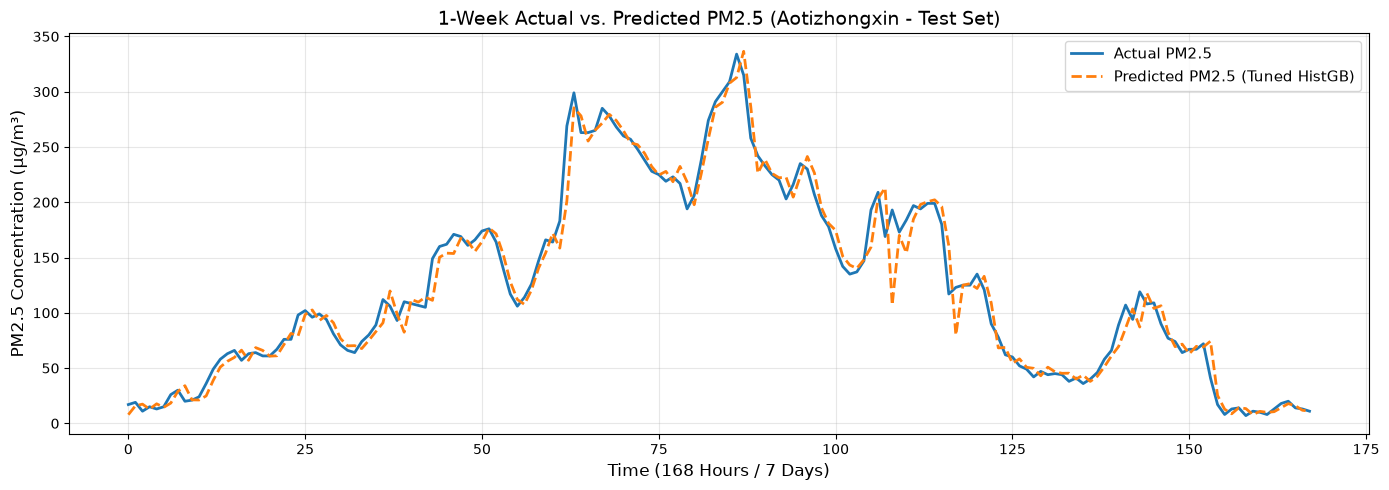

In [11]:
# Comparing actual and predicted data
week_slice = results_df[station_mask].iloc[:168]

plt.figure(figsize=(14, 5))

x_axis = range(len(week_slice))

plt.plot(x_axis, week_slice["Actual"], label="Actual PM2.5", color="#1f77b4", linewidth=2)
plt.plot(x_axis, week_slice["Predicted"], label="Predicted PM2.5 (Tuned HistGB)", color="#ff7f0e", linestyle="--", linewidth=2)

plt.title("1-Week Actual vs. Predicted PM2.5 (Aotizhongxin - Test Set)", fontsize=14)
plt.xlabel("Time (168 Hours / 7 Days)", fontsize=12)
plt.ylabel("PM2.5 Concentration (µg/m³)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
#plt.savefig("../reports/figures/actual_vs_predicted.png", dpi=300)
plt.show()

In [12]:
# Calculate feature importances
perm_imp = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=37, n_jobs=-1)

feature_imp = pd.Series(
    data=perm_imp.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

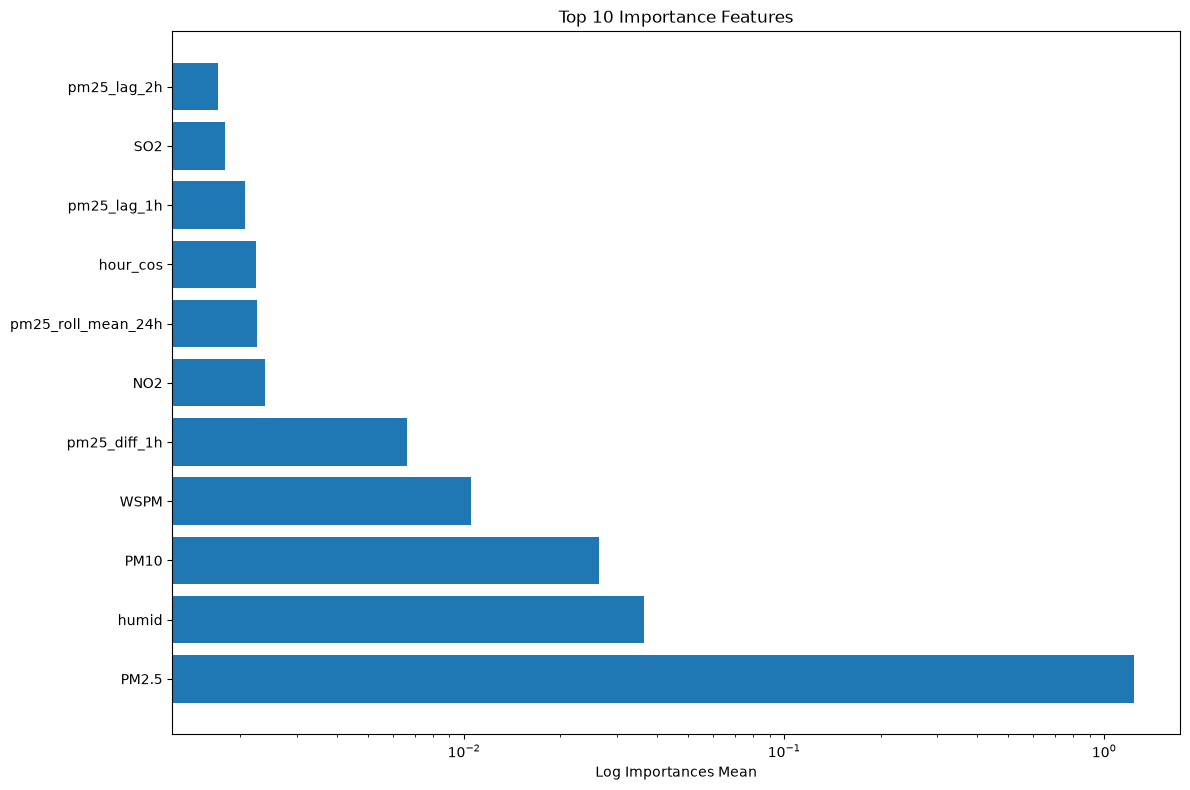

In [13]:
# Plot into bar chart
plt.figure(figsize=(12, 8))
plt.barh(
    y=feature_imp.index[:11],
    width=feature_imp.values[:11],
    log=True
)
plt.xlabel("Log Importances Mean")
plt.title("Top 10 Importance Features")

plt.tight_layout()
#plt.savefig("../reports/figures/feature_importances", dpi=300)
plt.show()

In [15]:
# Save the model
model_artifact = {
    "model": best_model,
    "feature_names": list(X_train.columns),
    "best_params": best_params,
    "test_metrics": {'MAE': 11.77, 'RMSE': 22.32, 'R2': 0.9477}
}

model_path = '../models/histgb_pm25_forecaster.joblib'
joblib.dump(model_artifact, model_path)

['../models/histgb_pm25_forecaster.joblib']